# Combined CheXpert and VinDr-CXR dataset

This notebook combines CheXpert and VinDr-CXR image dataset into a four-label dataset with training, validation, and test splits.


In [1]:
# Import libraries
import hashlib
import io
import json
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit

INPUT = Path('/kaggle/input')
OUTPUT = Path('/kaggle/working/chexpert_vindr_combined.zip')
SEED = 42
CHEXPERT_LIMIT = 10000
LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Pleural Effusion']
CLASS_IDS = {'Atelectasis': 1, 'Cardiomegaly': 3, 'Consolidation': 4, 'Pleural Effusion': 10}
KEYS = ['atelectasis', 'cardiomegaly', 'consolidation', 'pleural_effusion']
TARGETS = ['target_' + key for key in KEYS]
MASKS = ['mask_' + key for key in KEYS]
START = time.perf_counter()


In [2]:
# Find the attached CheXpert images, resized VinDr images, and VinDr labels
chexpert_options = [
    INPUT / 'chexpert',
    INPUT / 'datasets/ashery/chexpert',
]
chexpert_options += [path / 'CheXpert-v1.0-small' for path in chexpert_options]
CHEXPERT = next((path for path in chexpert_options if (path / 'train.csv').is_file() and (path / 'train').is_dir()), None)

vin_options = [
    INPUT / 'vinbigdata-chest-xray-resized-png-256x256',
    INPUT / 'datasets/xhlulu/vinbigdata-chest-xray-resized-png-256x256',
]
vin_options += [path / 'vinbigdata' for path in vin_options]
VIN_IMAGES = next((path / 'train' for path in vin_options if (path / 'train').is_dir()), None)

vin_csv_options = [
    INPUT / 'vinbigdata-chest-xray-abnormalities-detection/train.csv',
    INPUT / 'competitions/vinbigdata-chest-xray-abnormalities-detection/train.csv',
    *(path / 'train.csv' for path in vin_options),
]
VIN_CSV = next((path for path in vin_csv_options if path.is_file() and
                {'image_id', 'rad_id', 'class_id'}.issubset(pd.read_csv(path, nrows=0).columns)), None)

if CHEXPERT is None or VIN_IMAGES is None or VIN_CSV is None:
    raise FileNotFoundError(
        f'Missing input: CheXpert={CHEXPERT}, VinDr images={VIN_IMAGES}, VinDr train.csv={VIN_CSV}. '
        'Attach CheXpert-v1.0-small, VinBigData Chest X-ray Resized PNG (256x256), '
        'and the VinBigData annotation CSV input.'
    )
print('CheXpert:', CHEXPERT)
print('VinDr images:', VIN_IMAGES)
print('VinDr annotations:', VIN_CSV)


CheXpert: /kaggle/input/datasets/ashery/chexpert
VinDr images: /kaggle/input/datasets/xhlulu/vinbigdata-chest-xray-resized-png-256x256/train
VinDr annotations: /kaggle/input/competitions/vinbigdata-chest-xray-abnormalities-detection/train.csv


In [3]:
# Select frontal CheXpert images and preserve uncertain-label masks
chexpert_raw = pd.read_csv(CHEXPERT / 'train.csv', dtype=str, keep_default_na=False)
chexpert_raw = chexpert_raw.loc[chexpert_raw['Frontal/Lateral'].eq('Frontal')].copy()
chexpert_raw = chexpert_raw.sample(n=min(CHEXPERT_LIMIT, len(chexpert_raw)), random_state=SEED).reset_index(drop=True)
relative = chexpert_raw['Path'].str.replace('\\', '/', regex=False).str.extract(
    r'(train/patient\d+/study\d+/[^/]+\.(?:jpg|jpeg|png))$', expand=False)
if relative.isna().any():
    raise ValueError('Some CheXpert image paths do not match the expected train/patient/study format.')
chexpert = pd.DataFrame({
    'sample_id': 'chexpert:' + relative,
    'source_dataset': 'chexpert',
    'group_id': 'chexpert:' + relative.str.extract(r'/(patient\d+)/', expand=False),
    'source_path': relative.map(lambda value: str(CHEXPERT / value)),
})
for label, target, mask in zip(LABELS, TARGETS, MASKS):
    value = chexpert_raw[label].str.strip()
    chexpert[target] = value.isin(['1', '1.0']).astype('int8')
    chexpert[mask] = (~value.isin(['-1', '-1.0'])).astype('int8')
print(f'CheXpert selected: {len(chexpert):,} frontal images')


CheXpert selected: 10,000 frontal images


In [4]:
# Build four VinDr image labels using agreement from at least two readers
boxes = pd.read_csv(VIN_CSV, dtype={'image_id': str, 'rad_id': str})
required = {'image_id', 'rad_id', 'class_id'}
if not required.issubset(boxes.columns):
    raise ValueError('VinDr train.csv needs image_id, rad_id, and class_id columns.')
boxes['class_id'] = pd.to_numeric(boxes['class_id'], errors='raise').astype(int)
image_ids = sorted(boxes['image_id'].unique())
image_paths = {path.stem: path for path in VIN_IMAGES.iterdir() if path.suffix.lower() in {'.png', '.jpg', '.jpeg'}}
missing = set(image_ids) - set(image_paths)
if missing:
    raise FileNotFoundError(f'{len(missing)} labeled VinDr images are missing; example: {next(iter(missing))}')

votes = (boxes.loc[boxes['class_id'].isin(CLASS_IDS.values())]
         .drop_duplicates(['image_id', 'rad_id', 'class_id'])
         .groupby(['image_id', 'class_id'])['rad_id'].nunique())
vindr = pd.DataFrame({
    'sample_id': ['vindr:' + image_id for image_id in image_ids],
    'source_dataset': 'vindr',
    'group_id': ['vindr:' + image_id for image_id in image_ids],
    'source_path': [str(image_paths[image_id]) for image_id in image_ids],
})
for label, target, mask in zip(LABELS, TARGETS, MASKS):
    class_id = CLASS_IDS[label]
    vindr[target] = [int(votes.get((image_id, class_id), 0) >= 2) for image_id in image_ids]
    vindr[mask] = 1
print(f'VinDr labeled images: {len(vindr):,}')
print('VinDr positive counts:', dict(zip(LABELS, vindr[TARGETS].sum().tolist())))


VinDr labeled images: 15,000
VinDr positive counts: {'Atelectasis': 62, 'Cardiomegaly': 1817, 'Consolidation': 121, 'Pleural Effusion': 634}


In [5]:
# Make training, validation, and test splits for each source
first, holdout = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
                      .split(chexpert, groups=chexpert['group_id']))
val_in_holdout, test_in_holdout = next(GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
                                        .split(chexpert.iloc[holdout], groups=chexpert.iloc[holdout]['group_id']))
chexpert['split'] = 'train'
chexpert.loc[holdout[val_in_holdout], 'split'] = 'validation'
chexpert.loc[holdout[test_in_holdout], 'split'] = 'test'

rng = np.random.default_rng(SEED)
order = rng.permutation(len(vindr))
train_end = int(0.8 * len(vindr))
val_end = int(0.9 * len(vindr))
vindr['split'] = 'train'
vindr.loc[order[train_end:val_end], 'split'] = 'validation'
vindr.loc[order[val_end:], 'split'] = 'test'

combined = pd.concat([chexpert, vindr], ignore_index=True)
if combined.groupby('group_id')['split'].nunique().gt(1).any():
    raise ValueError('A group appears in more than one split.')
print(combined.groupby(['split', 'source_dataset']).size().rename('images').to_string())


split       source_dataset
test        chexpert           1001
            vindr              1500
train       chexpert           7973
            vindr             12000
validation  chexpert           1026
            vindr              1500


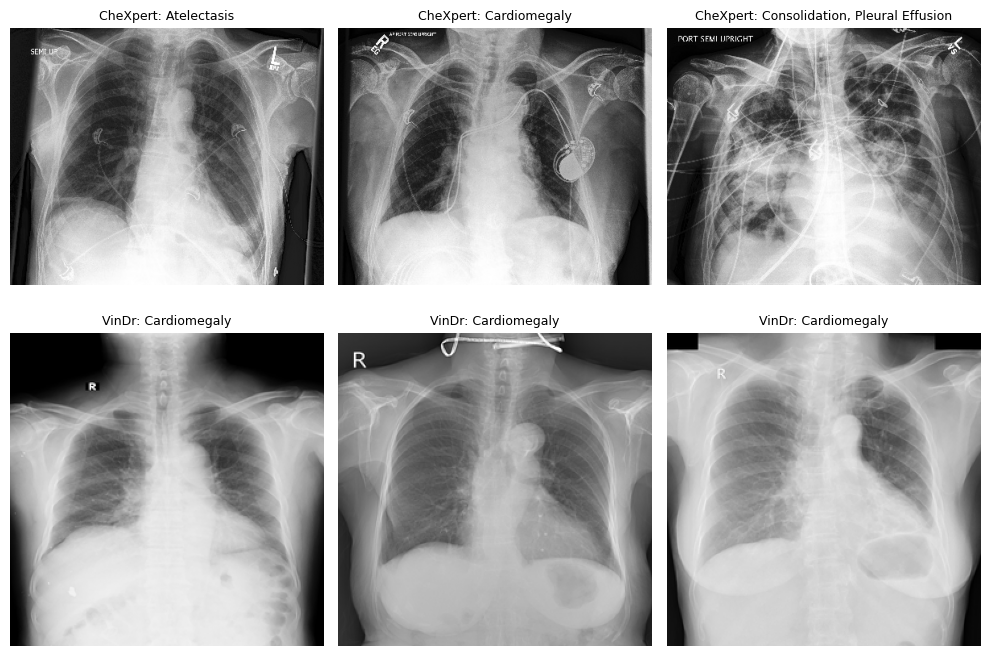

In [6]:
# Display a few source images before packaging
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for row, (name, frame) in enumerate([('CheXpert', chexpert), ('VinDr', vindr)]):
    positive = frame.loc[frame[TARGETS].any(axis=1)]
    examples = positive.sample(n=3, random_state=SEED)
    for col, (_, example) in enumerate(examples.iterrows()):
        with Image.open(example['source_path']) as image:
            axes[row, col].imshow(image.convert('L'), cmap='gray')
        labels = [label for label, target in zip(LABELS, TARGETS) if example[target] == 1]
        axes[row, col].set_title(f'{name}: {", ".join(labels[:2])}', fontsize=9)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()
plt.close(fig)


In [7]:
# Package the original image bytes and split labels into one ZIP
if OUTPUT.exists():
    raise FileExistsError(f'Output already exists: {OUTPUT}')
partial = OUTPUT.with_suffix('.zip.partial')
partial.unlink(missing_ok=True)
ordered = combined.sort_values(['split', 'source_dataset', 'sample_id']).reset_index(drop=True)
packaged = []
total = len(ordered)
print(f'Packaging {total:,} images...', flush=True)
try:
    with zipfile.ZipFile(partial, 'w', compression=zipfile.ZIP_STORED, allowZip64=True) as archive:
        for number, row in enumerate(ordered.itertuples(index=False), start=1):
            path = Path(row.source_path)
            name = hashlib.sha1(row.sample_id.encode()).hexdigest()[:20] + path.suffix.lower()
            inside = f'{row.split}/images/{row.source_dataset}/{name}'
            with path.open('rb') as source:
                archive.writestr(inside, source.read())
            packaged.append(inside)
            if number % 2500 == 0 or number == total:
                print(f'Packaged {number:,}/{total:,} images', flush=True)

        ordered['image_path'] = packaged
        columns = ['sample_id', 'source_dataset', 'group_id', 'image_path', *TARGETS, *MASKS]
        for split in ['train', 'validation', 'test']:
            labels = ordered.loc[ordered['split'].eq(split), columns]
            archive.writestr(f'{split}/labels.csv', labels.to_csv(index=False))
    partial.replace(OUTPUT)
except Exception:
    partial.unlink(missing_ok=True)
    raise
print(f'ZIP ready: {OUTPUT} ({OUTPUT.stat().st_size / 1024**3:.2f} GiB)', flush=True)


Packaging 25,000 images...
Packaged 2,500/25,000 images
Packaged 5,000/25,000 images
Packaged 7,500/25,000 images
Packaged 10,000/25,000 images
Packaged 12,500/25,000 images
Packaged 15,000/25,000 images
Packaged 17,500/25,000 images
Packaged 20,000/25,000 images
Packaged 22,500/25,000 images
Packaged 25,000/25,000 images
ZIP ready: /kaggle/working/chexpert_vindr_combined.zip (0.94 GiB)


In [8]:
# Check the packaged labels and show the Kaggle download link
with zipfile.ZipFile(OUTPUT) as archive:
    for split in ['train', 'validation', 'test']:
        labels = pd.read_csv(archive.open(f'{split}/labels.csv'))
        archive.read(labels['image_path'].iloc[0])
        print(f'{split}: {len(labels):,} images')
print(f'Preparation time: {(time.perf_counter() - START) / 60:.1f} minutes')
from IPython.display import FileLink, display
display(FileLink(str(OUTPUT)))


train: 19,973 images
validation: 2,526 images
test: 2,501 images
Preparation time: 251.0 minutes


/kaggle/working/chexpert_vindr_combined.zip